# Performance tests for find(x) in skiplist variations

In [1]:
import time
import random
import statistics

from ods.skip_list import SkiplistSSet, SkiplistWithFinger


def _populate(cls, n):
    sl = cls()
    for i in range(n):
        sl.add(i)
    return sl


def bench_find(cls, n, keys, repeats=5):
    """
    Median time per find() (microseconds) over `repeats` runs
    with the same key sequence.
    """
    per_run = []

    for _ in range(repeats):
        sl = _populate(cls, n)      # fresh instance + fresh finger each run
        start = time.perf_counter()
        for k in keys:
            sl.find(k)
        per_run.append(time.perf_counter() - start)

    total_ops = len(keys) * repeats
    return statistics.median(per_run) / total_ops * 1e6


def make_keys_random(n, ops):
    return [random.randrange(n) for _ in range(ops)]

def make_keys_sequential(n, ops):
    return [i % n for i in range(ops)]

def make_keys_local(n, ops, window=100):
    pos = random.randrange(n)
    keys = []
    for _ in range(ops):
        pos = min(n - 1, max(0, pos + random.randint(-window, window)))
        keys.append(pos)
    return keys

In [2]:
IMPLS = {
    "SkiplistSSet": SkiplistSSet,
    "SkiplistWithFinger": SkiplistWithFinger,
}

n_values = [1_000, 10_000, 50_000, 100_000, 200_000]
ops = 100_000

workloads = {
    "random": make_keys_random,
    "sequential": make_keys_sequential,
    "local": make_keys_local,
}

rows = []
for n in n_values:
    row = {"n, set size": n}
    for wl_name, make_keys in workloads.items():
        keys = make_keys(n, ops)          # same keys for both impls!
        for impl_name, cls in IMPLS.items():
            row[f"{wl_name} / {impl_name}"] = bench_find(cls, n, keys)
    rows.append(row)
    print(f"n={n} done")

n=1000 done
n=10000 done
n=50000 done
n=100000 done
n=200000 done


In [3]:
import pandas as pd

bench = pd.DataFrame(rows).set_index("n, set size")
bench.round(2)

,random / SkiplistSSet,random / SkiplistWithFinger,sequential / SkiplistSSet,sequential / SkiplistWithFinger,local / SkiplistSSet,local / SkiplistWithFinger
"n, set size",,,,,,
1000,0.37,0.42,0.24,0.16,0.24,0.32
10000,0.35,0.55,0.31,0.16,0.33,0.35
50000,0.49,0.78,0.40,0.17,0.41,0.35
100000,0.67,0.94,0.40,0.17,0.42,0.36
200000,0.77,1.05,0.43,0.17,0.47,0.35


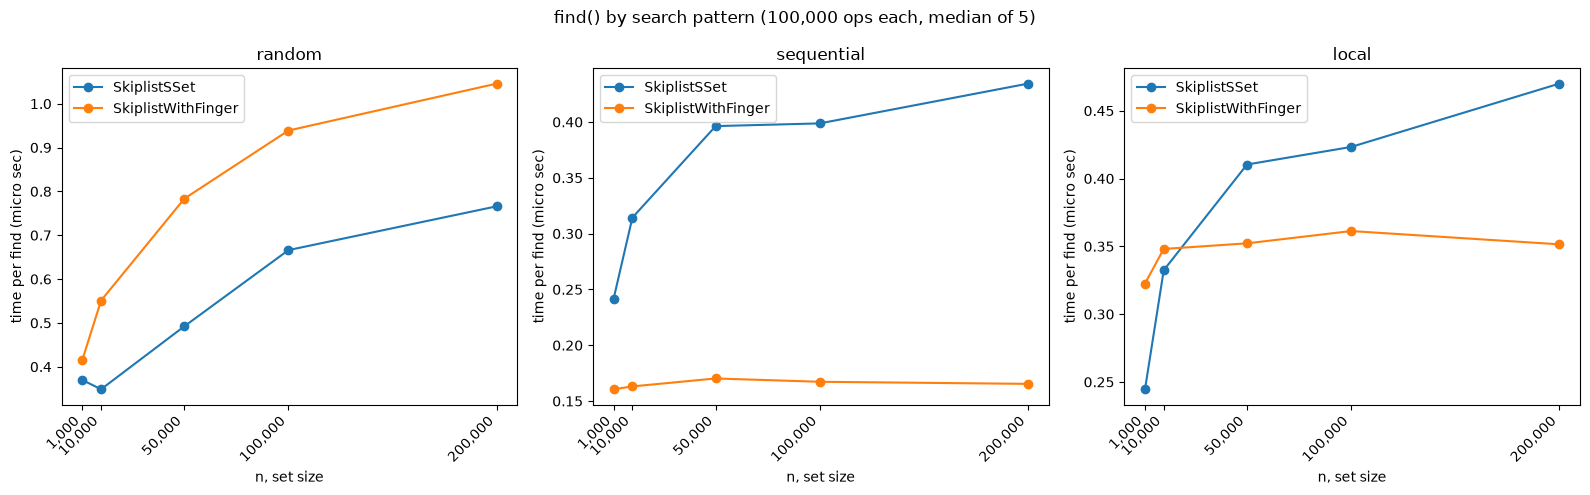

In [13]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, wl_name in zip(axes, workloads):
    cols = [c for c in bench.columns if c.startswith(wl_name)]
    for col in cols:
        ax.plot(bench.index, bench[col], marker="o", label=col.split(" / ")[1])
    ax.set_title(wl_name)
    ax.set_xlabel("n, set size")
    ax.set_ylabel("time per find (micro sec)")
    ax.set_xticks(n_values)
    ax.set_xticklabels([f"{n:,}" for n in n_values], rotation=45, ha="right")
    ax.legend()

plt.suptitle(f"find() by search pattern ({ops:,} ops each, median of 5)")
plt.tight_layout()
plt.show()